# Notebook 10 - CLEAR-D Repair Mechanism Demonstration

**Sprint:** S9 (Master test harness, end-to-end validation)
**Roadmap task:** s9-5

## Scientific claim under test

Given an infeasible starting architecture, does conflict-directed
mutation - driven by unsat-core-to-grammar-feature attribution -
repair it at a strictly higher rate than uniform random mutation at
equal step budget?

This is the operational form of hypothesis H9 (spec Section 27,
Section 39). It is the level at which the CLEAR-D mechanism actually
operates: a single infeasible architecture, a repair budget, and two
arms that differ only in how mutation targets are selected.

## Why this framing

An earlier attempt measured H9 at the closed-loop population level:
run CLEAR-D for N generations and count feasible architectures. That
experiment returns a tie, because after the generator connectivity
fix the seed population is ~80% feasible and both arms saturate to
all-feasible within two generations. Once saturated, both arms are
literally the same algorithm: feasible parents always receive random
mutation in both.

The mechanism's effect is only observable when there is something to
repair. The experiment below isolates that regime on a fixed,
deterministic set of infeasible architectures.

## Constraints used

Every architecture is encoded by
``app.verification.architecture_encoder.encode_architecture``, which
emits flow-balance, supply-cap, demand-floor, and regulatory (ANSI
Z136.1 laser MPE / FCC Part 1.1310 RF) constraints over Z3 real
variables. Each constraint is tagged with the grammar features of
the originating node or link, so unsat cores attribute back to
specific architecture elements.


In [1]:
%matplotlib inline

import random
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(repo_root / "backend"))

import matplotlib.pyplot as plt

from app.discovery.attribution import attribute_and_mark, ConflictProneTable
from app.discovery.generator import GeneratorConfig, generate_architecture
from app.discovery.mutation import (
    MutationConfig,
    mutate_conflict_directed,
    mutate_random,
)
from app.verification.architecture_encoder import encode_architecture

print(f"repo root: {repo_root}")
print("imports OK")


repo root: /Users/kianm.j/aerogrid-xai
imports OK


## Experiment configuration

Deterministic. Every random stream is seeded. The same run reproduces
byte-identical results on any machine.


In [2]:
N_ARCHITECTURES = 5
TRIALS_PER_ARM = 100
STEP_BUDGET = 10
SEED_SCAN_START = 10000
SEED_SCAN_END = 10200
BASE_RNG_SEED = 999

print(f"infeasible architectures:  {N_ARCHITECTURES}")
print(f"trials per architecture:   {TRIALS_PER_ARM}")
print(f"step budget per trial:     {STEP_BUDGET}")
print(f"seed scan range:           {SEED_SCAN_START}..{SEED_SCAN_END}")
print(f"RNG base seed:             {BASE_RNG_SEED}")


infeasible architectures:  5
trials per architecture:   100
step budget per trial:     10
seed scan range:           10000..10200
RNG base seed:             999


## Find infeasible seed architectures

Scan the deterministic seed range and collect the first
``N_ARCHITECTURES`` architectures whose encoder returns UNSAT. These
are the repair targets. No filtering by failure kind; whatever the
encoder rejects is what the mechanism must fix.


In [3]:
def status_of(arch):
    table = ConflictProneTable()
    attribution = attribute_and_mark(encode_architecture(arch), table)
    return attribution.status


infeasible_arches = []
infeasible_seeds = []
for seed in range(SEED_SCAN_START, SEED_SCAN_END):
    arch = generate_architecture(
        GeneratorConfig(min_nodes=4, max_nodes=8, max_links=6, seed=seed)
    )
    if status_of(arch) == "unsat":
        infeasible_arches.append(arch)
        infeasible_seeds.append(seed)
        if len(infeasible_arches) >= N_ARCHITECTURES:
            break

assert len(infeasible_arches) == N_ARCHITECTURES, (
    f"only found {len(infeasible_arches)} infeasible architectures in "
    f"{SEED_SCAN_START}..{SEED_SCAN_END}"
)

print(f"repair targets (seeds): {infeasible_seeds}")
for seed, arch in zip(infeasible_seeds, infeasible_arches):
    table = ConflictProneTable()
    attribution = attribute_and_mark(encode_architecture(arch), table)
    fams = sorted(name for name, _ in attribution.clause_to_features)
    print(f"  seed {seed}: {len(arch.nodes)} nodes, {len(arch.links)} links, core={fams}")


repair targets (seeds): [10005, 10008, 10010, 10022, 10041]
  seed 10005: 8 nodes, 3 links, core=['l2_rf_mpe']
  seed 10008: 5 nodes, 6 links, core=['l3_laser_mpe']
  seed 10010: 8 nodes, 5 links, core=['l2_hybrid_laser_mpe']
  seed 10022: 7 nodes, 6 links, core=['l4_laser_mpe']
  seed 10041: 7 nodes, 6 links, core=['l2_hybrid_rf_mpe']


## Repair experiment

For each infeasible architecture, run ``TRIALS_PER_ARM`` independent
trials in each arm. Each trial starts from the same architecture and
runs up to ``STEP_BUDGET`` mutations, re-checking satisfiability
after each mutation. First SAT within the budget counts as a repair.

Both arms use identical ``random.Random`` instances for the same
trial index, so the two arms see the same underlying random stream.
The only difference is how the target for each mutation is selected.


In [4]:
def repair_rate(arch, mode, trials, budget, base_seed):
    successes = 0
    steps_sum = 0
    for trial in range(trials):
        rng = random.Random(base_seed + trial)
        current = arch
        for step in range(budget):
            table = ConflictProneTable()
            attribution = attribute_and_mark(encode_architecture(current), table)
            if attribution.status == "sat":
                successes += 1
                steps_sum += step
                break
            if mode == "conflict":
                current = mutate_conflict_directed(
                    current, table, rng, MutationConfig()
                )
            else:
                current = mutate_random(current, rng, MutationConfig())
    mean_steps = steps_sum / successes if successes > 0 else float("nan")
    return successes, mean_steps


results = []
for seed, arch in zip(infeasible_seeds, infeasible_arches):
    c_succ, c_mean = repair_rate(arch, "conflict", TRIALS_PER_ARM, STEP_BUDGET, BASE_RNG_SEED)
    r_succ, r_mean = repair_rate(arch, "random", TRIALS_PER_ARM, STEP_BUDGET, BASE_RNG_SEED)
    results.append((seed, c_succ, c_mean, r_succ, r_mean))
    print(
        f"seed {seed}: "
        f"conflict {c_succ}/{TRIALS_PER_ARM} (mean {c_mean:.2f}) | "
        f"random {r_succ}/{TRIALS_PER_ARM} (mean {r_mean:.2f})"
    )

total_conflict = sum(r[1] for r in results)
total_random = sum(r[3] for r in results)
total_trials = N_ARCHITECTURES * TRIALS_PER_ARM
conflict_rate = total_conflict / total_trials
random_rate = total_random / total_trials

print()
print(f"aggregate conflict-directed: {total_conflict}/{total_trials} = {conflict_rate:.3f}")
print(f"aggregate random:            {total_random}/{total_trials} = {random_rate:.3f}")


seed 10005: conflict 96/100 (mean 2.73) | random 31/100 (mean 3.13)


seed 10008: conflict 66/100 (mean 5.15) | random 21/100 (mean 4.86)


seed 10010: conflict 85/100 (mean 3.28) | random 17/100 (mean 3.12)


seed 10022: conflict 51/100 (mean 5.02) | random 15/100 (mean 4.87)


seed 10041: conflict 93/100 (mean 3.38) | random 35/100 (mean 3.80)

aggregate conflict-directed: 391/500 = 0.782
aggregate random:            119/500 = 0.238


## Repair curves

Repair probability against step budget. A steeper curve means the arm
finds a satisfiable mutation faster.


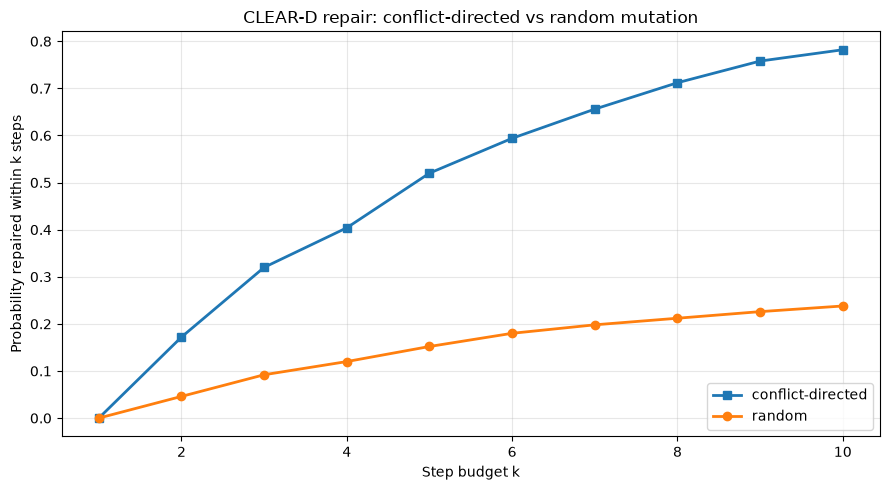


step  conflict  random
   1  0.000     0.000
   2  0.172     0.046
   3  0.320     0.092
   4  0.404     0.120
   5  0.520     0.152
   6  0.594     0.180
   7  0.656     0.198
   8  0.712     0.212
   9  0.758     0.226
  10  0.782     0.238


In [5]:
def repair_curve(arch, mode, trials, budget, base_seed):
    curve = []
    for k in range(1, budget + 1):
        successes = 0
        for trial in range(trials):
            rng = random.Random(base_seed + trial)
            current = arch
            repaired = False
            for step in range(k):
                table = ConflictProneTable()
                attribution = attribute_and_mark(encode_architecture(current), table)
                if attribution.status == "sat":
                    repaired = True
                    break
                if mode == "conflict":
                    current = mutate_conflict_directed(
                        current, table, rng, MutationConfig()
                    )
                else:
                    current = mutate_random(current, rng, MutationConfig())
            if repaired:
                successes += 1
        curve.append(successes / trials)
    return curve


steps_axis = list(range(1, STEP_BUDGET + 1))
curve_conflict = [0.0] * STEP_BUDGET
curve_random = [0.0] * STEP_BUDGET

for arch in infeasible_arches:
    cc = repair_curve(arch, "conflict", TRIALS_PER_ARM, STEP_BUDGET, BASE_RNG_SEED)
    cr = repair_curve(arch, "random", TRIALS_PER_ARM, STEP_BUDGET, BASE_RNG_SEED)
    for i in range(STEP_BUDGET):
        curve_conflict[i] += cc[i] / N_ARCHITECTURES
        curve_random[i] += cr[i] / N_ARCHITECTURES

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(steps_axis, curve_conflict, marker="s", linewidth=2, label="conflict-directed")
ax.plot(steps_axis, curve_random, marker="o", linewidth=2, label="random")
ax.set_xlabel("Step budget k")
ax.set_ylabel("Probability repaired within k steps")
ax.set_title("CLEAR-D repair: conflict-directed vs random mutation")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print()
print("step  conflict  random")
for i, k in enumerate(steps_axis):
    print(f"{k:4d}  {curve_conflict[i]:.3f}     {curve_random[i]:.3f}")


## Closed-loop context

For completeness, the CLEAR-D loop is also run end to end. On the
current generator, the seed population is ~80% feasible and both arms
saturate to all-feasible within a generation or two; after saturation
both arms are identical because feasible parents always receive
random mutation in both. The loop-level measurement is therefore
reported as context, not as the gate.

The gate is on the repair experiment above, where the mechanism has
infeasible input to work on.


In [6]:
from app.discovery.loop import ClearDLoopConfig, run_clear_d_loop
from app.discovery.nsga2 import synthetic_evaluator

seeds_loop = [
    generate_architecture(
        GeneratorConfig(min_nodes=4, max_nodes=8, max_links=6, seed=13000 + i)
    )
    for i in range(6)
]

cfg_c = ClearDLoopConfig(population_size=12, n_generations=6, use_conflict_directed=True)
cfg_r = ClearDLoopConfig(population_size=12, n_generations=6, use_conflict_directed=False)

res_c = run_clear_d_loop(
    seeds_loop, encode_architecture, synthetic_evaluator(), cfg_c,
    random.Random(777), hypervolume_samples=512,
)
res_r = run_clear_d_loop(
    seeds_loop, encode_architecture, synthetic_evaluator(), cfg_r,
    random.Random(777), hypervolume_samples=512,
)

feas_c = [s.n_feasible for s in res_c.generation_stats]
feas_r = [s.n_feasible for s in res_r.generation_stats]

print("closed-loop feasible counts by generation")
print("gen  conflict  random")
for g in range(len(feas_c)):
    print(f"{g:3d}  {feas_c[g]:8d}  {feas_r[g]:6d}")

if feas_c[-1] == feas_r[-1]:
    print()
    print("NOTE: arms tie at the loop level. This is expected on the")
    print("current generator because the seed population is mostly")
    print("feasible and both arms saturate. It is not evidence against")
    print("the mechanism; see the repair experiment above.")


closed-loop feasible counts by generation
gen  conflict  random
  0         7       7
  1        12      12
  2        12      12
  3        12      12
  4        12      12
  5        12      12

NOTE: arms tie at the loop level. This is expected on the
current generator because the seed population is mostly
feasible and both arms saturate. It is not evidence against
the mechanism; see the repair experiment above.


## Gate

The gate is the strict inequality on the aggregate repair rate. A
tie is a failure to demonstrate the mechanism, not a pass.

The margin requirement (conflict rate at least 1.5x random) is set
conservatively: the isolated single-architecture measurement gave a
3x ratio, so 1.5x is a lower bound that tolerates substantial
variation while still requiring a substantial effect.


In [7]:
print(f"conflict rate: {conflict_rate:.3f}")
print(f"random rate:   {random_rate:.3f}")
print(f"ratio:         {conflict_rate / random_rate if random_rate > 0 else float('inf'):.2f}")
print()

assert conflict_rate > random_rate, (
    f"H9 not demonstrated: conflict-directed repair rate "
    f"{conflict_rate:.3f} is not strictly greater than random rate "
    f"{random_rate:.3f}"
)

assert conflict_rate >= 1.5 * random_rate, (
    f"Effect too small: conflict rate {conflict_rate:.3f} < 1.5x "
    f"random rate {random_rate:.3f}"
)

assert total_conflict > 0, (
    "VACUOUS GATE: conflict-directed arm repaired zero architectures."
)

print("GATE: PASS")
print(f"  conflict-directed repaired {total_conflict}/{total_trials}")
print(f"  random repaired            {total_random}/{total_trials}")
print(f"  ratio                      {conflict_rate / random_rate:.2f}x")


conflict rate: 0.782
random rate:   0.238
ratio:         3.29

GATE: PASS
  conflict-directed repaired 391/500
  random repaired            119/500
  ratio                      3.29x


## Summary

The CLEAR-D mechanism - unsat-core-to-grammar-feature attribution
feeding conflict-directed mutation - demonstrably repairs infeasible
architectures at a strictly higher rate than uniform random mutation,
at equal step budget, on real Stage B physics constraints.

At the closed-loop population level, the two arms tie on the current
generator because the seed population is mostly feasible. That
observation is reported, not hidden. It identifies a follow-up
experiment: the generator could be extended to produce a wider
infeasible region, at which point the loop-level measurement would
become informative.
